# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('../data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


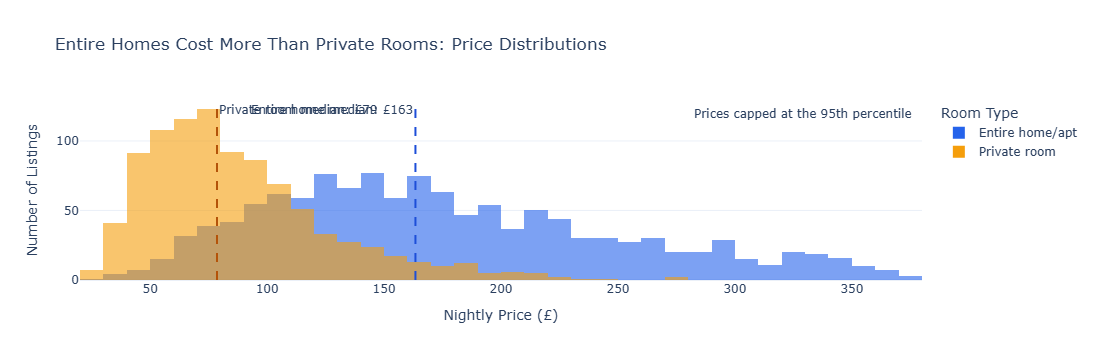

Median prices:
room_type
Entire home/apt    163.42
Private room        78.57
Name: price, dtype: float64


In [4]:
# Task 1
# YOUR CODE HERE
# Task 1: Price distribution by room type

import plotly.graph_objects as go

# Select the two room types and exclude prices above the 95th percentile
df_task1 = df_cap[
    df_cap["room_type"].isin(["Entire home/apt", "Private room"])
].copy()

# Calculate the median price for each room type
medians = df_task1.groupby("room_type")["price"].median()

# Create the overlapping histogram
fig = px.histogram(
    df_task1,
    x="price",
    color="room_type",
    barmode="overlay",
    opacity=0.6,
    nbins=40,
    title="Entire Homes Cost More Than Private Rooms: Price Distributions",
    labels={
        "price": "Nightly Price (£)",
        "room_type": "Room Type"
    },
    color_discrete_map={
        "Entire home/apt": "#2563eb",
        "Private room": "#f59e0b"
    }
)

# Add a separate median reference line for each room type
fig.add_vline(
    x=medians["Entire home/apt"],
    line_color="#1d4ed8",
    line_dash="dash",
    annotation_text=f"Entire home median: £{medians['Entire home/apt']:.0f}",
    annotation_position="top left"
)

fig.add_vline(
    x=medians["Private room"],
    line_color="#b45309",
    line_dash="dash",
    annotation_text=f"Private room median: £{medians['Private room']:.0f}",
    annotation_position="top right"
)

fig.add_annotation(
    x=0.99,
    y=0.98,
    xref="paper",
    yref="paper",
    text="Prices capped at the 95th percentile",
    showarrow=False,
    xanchor="right",
    yanchor="top"
)

fig.update_layout(
    xaxis_title="Nightly Price (£)",
    yaxis_title="Number of Listings",
    legend_title="Room Type",
    template="plotly_white"
)

fig.show()

print("Median prices:")
print(medians.round(2))


## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

Two most active boroughs:
neighbourhood
Tower Hamlets    1.75
Hackney          1.66
Name: reviews_per_month, dtype: float64


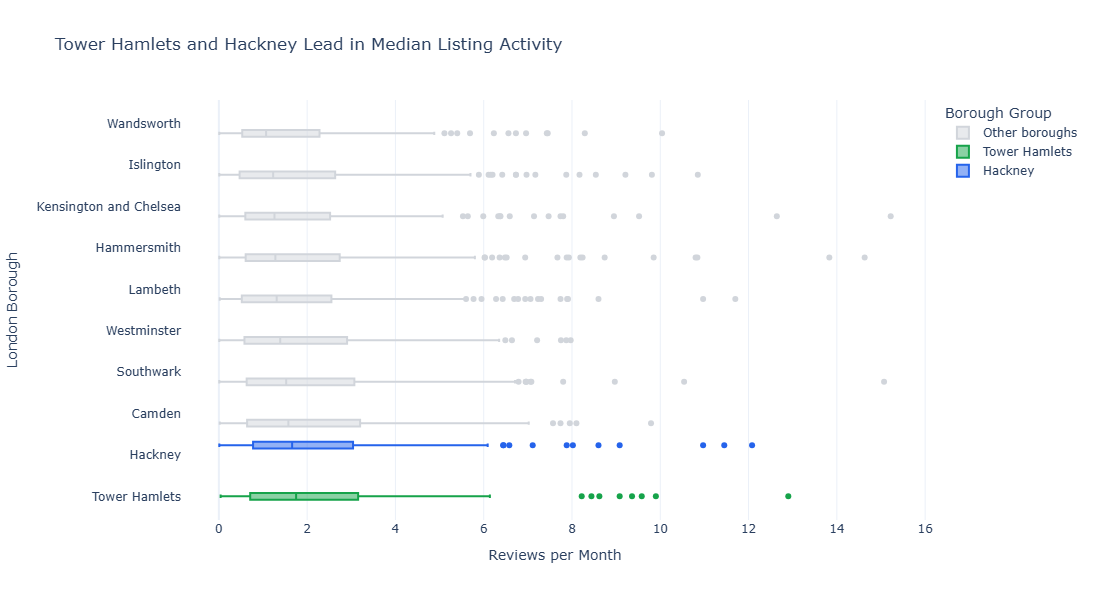


Median reviews per month by borough:
neighbourhood
Tower Hamlets             1.75
Hackney                   1.66
Camden                    1.58
Southwark                 1.52
Westminster               1.39
Lambeth                   1.31
Hammersmith               1.28
Kensington and Chelsea    1.26
Islington                 1.23
Wandsworth                1.07
Name: reviews_per_month, dtype: float64


In [5]:
# Task 2
# YOUR CODE HERE
# Task 2: Listing activity by London borough

# Remove listings with zero reviews per month or missing values
df_task2 = df.dropna(
    subset=["neighbourhood", "reviews_per_month"]
).copy()

df_task2 = df_task2[df_task2["reviews_per_month"] > 0]

# Calculate median activity for each borough
borough_medians = (
    df_task2.groupby("neighbourhood")["reviews_per_month"]
    .median()
    .sort_values(ascending=False)
)

# Identify the two most active boroughs
top_two = borough_medians.head(2).index.tolist()

print("Two most active boroughs:")
print(borough_medians.head(2))

# Assign meaningful colours to the top two boroughs
df_task2["activity_group"] = np.where(
    df_task2["neighbourhood"].isin(top_two),
    df_task2["neighbourhood"],
    "Other boroughs"
)

colour_map = {
    top_two[0]: "#16a34a",
    top_two[1]: "#2563eb",
    "Other boroughs": "#d1d5db"
}

# Sort boroughs by median activity, highest first
borough_order = borough_medians.index.tolist()

# Create horizontal box plot
fig = px.box(
    df_task2,
    x="reviews_per_month",
    y="neighbourhood",
    color="activity_group",
    category_orders={"neighbourhood": borough_order[::-1]},
    color_discrete_map=colour_map,
    points="outliers",
    title=(
        f"{top_two[0]} and {top_two[1]} Lead in Median "
        "Listing Activity"
    ),
    labels={
        "reviews_per_month": "Reviews per Month",
        "neighbourhood": "London Borough",
        "activity_group": "Activity Group"
    }
)

fig.update_layout(
    xaxis_title="Reviews per Month",
    yaxis_title="London Borough",
    legend_title="Borough Group",
    template="plotly_white",
    height=max(600, len(borough_order) * 22)
)

fig.show()

print("\nMedian reviews per month by borough:")
print(borough_medians.round(2))